# 02 — Data Understanding
**Objective:** Understand every table: size, columns, data types, keys, and relationships.
**Deliverable:** Dataset documentation and data dictionary.

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

In [2]:
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)


PROJECT_ROOT = Path.cwd().parent
RAW_DIR = PROJECT_ROOT / "data" / "raw"

files = {
    "customers":   "customers.csv",
    "geolocation": "geolocation.csv",
    "order_items": "order_items.csv",
    "payments":    "order_payments.csv",
    "reviews":     "order_review.csv",
    "orders":      "orders.csv",
    "products":    "products.csv",
    "sellers":     "sellers.csv",
    "translation": "product_category_name.csv",
}

data = {name: pd.read_csv(RAW_DIR / f) for name, f in files.items()}
print("All tables loaded:", list(data.keys()))

All tables loaded: ['customers', 'geolocation', 'order_items', 'payments', 'reviews', 'orders', 'products', 'sellers', 'translation']


In [3]:
# overview of all tables

overview = pd.DataFrame({
    "table": list(data.keys()),
    "rows": [df.shape[0] for df in data.values()],
    "columns": [df.shape[1] for df in data.values()],
    "memory_mb": [round(df.memory_usage(deep = True).sum() / 1e6, 2) for df in data.values()],
    "missing_cells": [int(df.isna().sum().sum()) for df in data.values()],
    "duplicate_rows": [int(df.duplicated().sum()) for df in data.values()],
}).set_index("table")

overview

,rows,columns,memory_mb,missing_cells,duplicate_rows
table,,,,,
customers,99441,5,31.06,0,0
geolocation,1000163,5,152.26,0,261831
order_items,112650,7,41.34,0,0
payments,103886,5,18.68,0,0
reviews,99224,7,44.82,145903,0
orders,99441,8,61.83,4908,0
products,32951,9,7.12,2448,0
sellers,3095,4,0.69,0,0
translation,71,2,0.01,0,0


In [4]:
for name, df in data.items():
    print(f"\n{'='*770}\n{name.upper()} | shape = {df.shape}\n{'='*70}")
    display(df.head(3))
    print(df.dtypes.to_string())


CUSTOMERS | shape = (99441, 5)


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP


customer_id                   str
customer_unique_id            str
customer_zip_code_prefix    int64
customer_city                 str
customer_state                str

GEOLOCATION | shape = (1000163, 5)


,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
0,1037,-23.55,-46.64,sao paulo,SP
1,1046,-23.55,-46.64,sao paulo,SP
2,1046,-23.55,-46.64,sao paulo,SP


geolocation_zip_code_prefix      int64
geolocation_lat                float64
geolocation_lng                float64
geolocation_city                   str
geolocation_state                  str

ORDER_ITEMS | shape = (112650, 7)


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87


... (9 outputs left out)

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ


seller_id                   str
seller_zip_code_prefix    int64
seller_city                 str
seller_state                str

TRANSLATION | shape = (71, 2)


,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto


product_category_name            str
product_category_name_english    str


In [5]:
# unique values per column
for name, df in data.items():
    summary = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "n_unique": df.nunique(),
        "n_missing": df.isna().sum(),
        "pct_missing": (df.isna().mean() * 100).round(2)
    })

    print(f"\n---- {name.upper()} ----")
    display(summary)


---- CUSTOMERS ----


,dtype,n_unique,n_missing,pct_missing
customer_id,str,99441,0,0.00
customer_unique_id,str,96096,0,0.00
customer_zip_code_prefix,int64,14994,0,0.00
customer_city,str,4119,0,0.00
customer_state,str,27,0,0.00



---- GEOLOCATION ----


,dtype,n_unique,n_missing,pct_missing
geolocation_zip_code_prefix,int64,19015,0,0.00
geolocation_lat,float64,717372,0,0.00
geolocation_lng,float64,717615,0,0.00
geolocation_city,str,8011,0,0.00
geolocation_state,str,27,0,0.00



---- ORDER_ITEMS ----


,dtype,n_unique,n_missing,pct_missing
order_id,str,98666,0,0.00
order_item_id,int64,21,0,0.00
product_id,str,32951,0,0.00
seller_id,str,3095,0,0.00
shipping_limit_date,str,93318,0,0.00
price,float64,5968,0,0.00
freight_value,float64,6999,0,0.00


... (8 outputs left out)


---- SELLERS ----


,dtype,n_unique,n_missing,pct_missing
seller_id,str,3095,0,0.00
seller_zip_code_prefix,int64,2246,0,0.00
seller_city,str,611,0,0.00
seller_state,str,23,0,0.00



---- TRANSLATION ----


,dtype,n_unique,n_missing,pct_missing
product_category_name,str,71,0,0.00
product_category_name_english,str,71,0,0.00


In [6]:
# verify primary keys

def check_key(df, cols, name):
    cols = [cols] if isinstance(cols, str) else cols
    is_unique = not df.duplicated(subset= cols).any()
    print(f"{name:12s} key {str(cols):.45s} unique: {is_unique}")

check_key(data["customers"],   "customer_id", "customers")
check_key(data["orders"],      "order_id", "orders")
check_key(data["order_items"], ["order_id", "order_item_id"], "order_items")
check_key(data["payments"],    ["order_id", "payment_sequential"], "payments")
check_key(data["reviews"],     "review_id", "reviews")
check_key(data["reviews"],     "order_id", "reviews")   # expect False
check_key(data["products"],    "product_id", "products")
check_key(data["sellers"],     "seller_id", "sellers")
check_key(data["translation"], "product_category_name", "translation")

customers    key ['customer_id'] unique: True
orders       key ['order_id'] unique: True
order_items  key ['order_id', 'order_item_id'] unique: True
payments     key ['order_id', 'payment_sequential'] unique: True
reviews      key ['review_id'] unique: False
reviews      key ['order_id'] unique: False
products     key ['product_id'] unique: True
sellers      key ['seller_id'] unique: True
translation  key ['product_category_name'] unique: True


In [7]:
# verify foreign keys (referential integrity)

def check_fk(child, child_col, parent, parent_col, label):
    child_vals = set(child[child_col].dropna().unique())
    parent_vals = set(parent[parent_col].unique())
    orphans = child_vals - parent_vals
    print(f"{label:40s} orphan values: {len(orphans)}")

check_fk(data["orders"],      "customer_id", data["customers"], "customer_id", "orders -> customers")
check_fk(data["order_items"], "order_id",    data["orders"],    "order_id",    "order_items -> orders")
check_fk(data["order_items"], "product_id",  data["products"],  "product_id",  "order_items -> products")
check_fk(data["order_items"], "seller_id",   data["sellers"],   "seller_id",   "order_items -> sellers")
check_fk(data["payments"],    "order_id",    data["orders"],    "order_id",    "payments -> orders")
check_fk(data["reviews"],     "order_id",    data["orders"],    "order_id",    "reviews -> orders")
check_fk(data["products"],    "product_category_name", data["translation"], "product_category_name", "products -> translation")

orders -> customers                      orphan values: 0
order_items -> orders                    orphan values: 0
order_items -> products                  orphan values: 0
order_items -> sellers                   orphan values: 0
payments -> orders                       orphan values: 0
reviews -> orders                        orphan values: 0
products -> translation                  orphan values: 2


In [8]:
# customer_id vs customer_unique_id

c = data["customers"]
print("Unique customer_id:       ", c["customer_id"].nunique())
print("Unique customer_unique_id:", c["customer_unique_id"].nunique())
print("Customers with >1 order id:", (c.groupby("customer_unique_id")["customer_id"].nunique() > 1).sum())

Unique customer_id:        99441
Unique customer_unique_id: 96096
Customers with >1 order id: 2997


In [15]:
# order status and date range

o = data["orders"].copy()
print(o["order_status"].value_counts(), "\n")

date_cols = ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date",
             "order_delivered_customer_date", "order_estimated_delivery_date"]
for col in date_cols:
    o[col] = pd.to_datetime(o[col], errors="coerce")
    print(f"{col:35s} {o[col].min()}  ->  {o[col].max()}")

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64 

order_purchase_timestamp            2016-09-04 21:15:19  ->  2018-10-17 17:30:18
order_approved_at                   2016-09-15 12:16:38  ->  2018-09-03 17:40:06
order_delivered_carrier_date        2016-10-08 10:34:01  ->  2018-09-11 19:48:28
order_delivered_customer_date       2016-10-11 13:46:32  ->  2018-10-17 13:22:46
order_estimated_delivery_date       2016-09-30 00:00:00  ->  2018-11-12 00:00:00


## Table relationships

| Table | Primary key | Foreign keys | Relationship |
|-------|-------------|--------------|--------------|
| customers | customer_id | - | One row per order-customer link; `customer_unique_id` = real person |
| orders | order_id | customer_id | Many orders can link to one unique customer |
| order_items | order_id + order_item_id | order_id, product_id, seller_id | One order has many items |
| order_payments | order_id + payment_sequential | order_id | One order can have several payments |
| order_reviews | review_id | order_id | Review per order (check duplicates) |
| products | product_id | product_category_name | Product details |
| sellers | seller_id | - | Seller location |
| geolocation | none (zip prefix, repeated) | - | Lat/lng by zip code prefix |
| translation | product_category_name | - | Portuguese to English categories |

In [11]:
# ER diagram
import matplotlib.pyplot as plt
import matplotlib.patches as patches

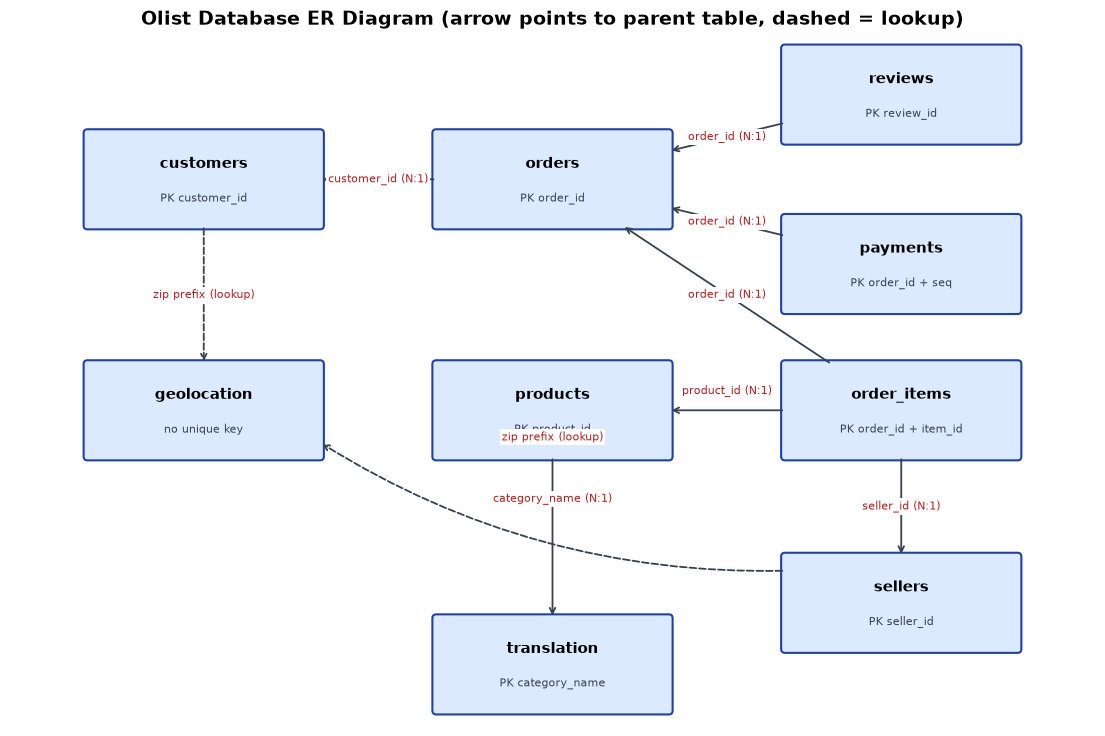

In [19]:
fig, ax = plt.subplots(figsize=(14, 9))
ax.set_xlim(0, 14); ax.set_ylim(0, 9); ax.axis("off")

w, h = 3, 1.2
boxes = {
    "customers":   (1, 6.5),
    "orders":      (5.5, 6.5),
    "reviews":     (10, 7.6),
    "payments":    (10, 5.4),
    "products":    (5.5, 3.5),
    "order_items": (10, 3.5),
    "sellers":     (10, 1.0),
    "translation": (5.5, 0.2),
    "geolocation": (1, 3.5),
}
keys = {
    "customers": "PK customer_id",
    "orders": "PK order_id",
    "reviews": "PK review_id",
    "payments": "PK order_id + seq",
    "products": "PK product_id",
    "order_items": "PK order_id + item_id",
    "sellers": "PK seller_id",
    "translation": "PK category_name",
    "geolocation": "no unique key",
}

for name, (x, y) in boxes.items():
    ax.add_patch(patches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.05",
                                        fc="#dbeafe", ec="#1e40af", lw=1.5))
    ax.text(x + w/2, y + h/2 + 0.2, name, ha="center", va="center", fontsize=11, weight="bold")
    ax.text(x + w/2, y + h/2 - 0.25, keys[name], ha="center", va="center", fontsize=8, color="#374151")

def anchor(name, toward):
    x, y = boxes[name]; cx, cy = x + w/2, y + h/2
    dx, dy = toward[0] - cx, toward[1] - cy
    sx = (w/2) / abs(dx) if dx else float("inf")
    sy = (h/2) / abs(dy) if dy else float("inf")
    s = min(sx, sy)
    return cx + dx * s, cy + dy * s

def link(child, parent, label, dashed=False, dy=0.0, rad=0.0):
    cc = (boxes[child][0] + w/2, boxes[child][1] + h/2)
    pc = (boxes[parent][0] + w/2, boxes[parent][1] + h/2)
    start, end = anchor(child, pc), anchor(parent, cc)
    ax.annotate("", xy=end, xytext=start,
                arrowprops=dict(arrowstyle="->", color="#374151", lw=1.3,
                                linestyle="--" if dashed else "-",
                                connectionstyle=f"arc3,rad={rad}"))
    mx, my = (start[0] + end[0]) / 2, (start[1] + end[1]) / 2 + dy
    ax.text(mx, my, label, fontsize=8, ha="center", va="center", color="#b91c1c",
            bbox=dict(fc="white", ec="none", pad=1.5))

link("orders", "customers", "customer_id (N:1)")
link("order_items", "orders", "order_id (N:1)")
link("payments", "orders", "order_id (N:1)")
link("reviews", "orders", "order_id (N:1)")
link("order_items", "products", "product_id (N:1)", dy=0.25)
link("order_items", "sellers", "seller_id (N:1)")
link("products", "translation", "category_name (N:1)", dy=0.5)
link("customers", "geolocation", "zip prefix (lookup)", dashed=True)
link("sellers", "geolocation", "zip prefix (lookup)", dashed=True, rad=-0.15, dy=0.9)
ax.set_title("Olist Database ER Diagram (arrow points to parent table, dashed = lookup)",
             fontsize=14, weight="bold")
(PROJECT_ROOT / "reports" / "figures").mkdir(parents=True, exist_ok=True)
plt.savefig(PROJECT_ROOT / "reports" / "figures" / "er_diagram.png", dpi=150, bbox_inches="tight")
plt.show()

In [17]:
# save the data dictionary

dd_rows = []
for name, df in data.items():
    for col in df.columns:
        dd_rows.append({
            "table": name, "column": col, "dtype": str(df[col].dtype),
            "n_unique": df[col].nunique(), "pct_missing": round(df[col].isna().mean() * 100, 2),
            "example": df[col].dropna().iloc[0] if df[col].notna().any() else None,
            "business_meaning": "",   # fill in manually
        })
data_dictionary = pd.DataFrame(dd_rows)

out = PROJECT_ROOT / "reports" / "data_dictionary.csv"
data_dictionary.to_csv(out, index=False)
print("Saved:", out)
data_dictionary.head(10)

Saved: c:\Users\ASUS\Desktop\AI_Projects\E-commerce-customer-analytics\reports\data_dictionary.csv


,table,column,dtype,n_unique,pct_missing,example,business_meaning
0,customers,customer_id,str,99441,0.00,06b8999e2fba1a1fbc88172c00ba8bc7,
1,customers,customer_unique_id,str,96096,0.00,861eff4711a542e4b93843c6dd7febb0,
2,customers,customer_zip_code_prefix,int64,14994,0.00,14409,
3,customers,customer_city,str,4119,0.00,franca,
4,customers,customer_state,str,27,0.00,SP,
5,geolocation,geolocation_zip_code_prefix,int64,19015,0.00,1037,
6,geolocation,geolocation_lat,float64,717372,0.00,-23.55,
7,geolocation,geolocation_lng,float64,717615,0.00,-46.64,
8,geolocation,geolocation_city,str,8011,0.00,sao paulo,
9,geolocation,geolocation_state,str,27,0.00,SP,


## Key findings
- **Size:** 9 tables. The largest is geolocation (~1.0M rows), then order_items (112,650), payments (103,886), orders and customers (99,441 each), and reviews (99,224).
- **Primary keys:** all are unique except `reviews`: 814 repeated review_id values, and some orders have more than one review (98,673 unique order_id in 99,224 rows).
- **Foreign keys:** no orphan values, except 2 product categories without an English translation.
- **Customer identity:** 99,441 customer_id vs 96,096 customer_unique_id. Only 2,997 people (~3.1%) have more than one order, so repeat purchasing is rare.
- **Order status:** 97% delivered (96,478); the rest are shipped, canceled, unavailable, invoiced, processing, created or approved.
- **Date range:** purchases from Sep 2016 to Oct 2018.
- **Missing values:** review comments are mostly empty (optional); 2,965 missing delivery dates; 610 products missing category and listing details.
- **Geolocation:** 261,831 duplicate rows (26%); must be aggregated to one row per zip prefix before any join.
- **Issues to investigate in notebook 3:**
  1. Delivered orders with missing delivery dates
  2. Orders with no items or no payments
  3. Duplicate / multiple reviews per order
  4. Illogical timestamp order (e.g. delivered before purchase)
  5. Payment total vs item price + freight mismatch
  6. Zero or negative prices, payments, extreme delivery durations
  7. Sparse 2016 data